In [1]:
import pandas as pd
import urllib.request
import zipfile

# Download the UCI Online Retail dataset
url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
urllib.request.urlretrieve(url, "online_retail.zip")

# Unzip it into a folder called "data"
with zipfile.ZipFile("online_retail.zip") as z:
    print("Files inside the zip:", z.namelist())
    z.extractall("data")

# Read the Excel file into a table (this can take 1-2 minutes)
df = pd.read_excel("data/Online Retail.xlsx")

# Show the size of the table and the first 5 rows
print("Rows and columns:", df.shape)
df.head()

Files inside the zip: ['Online Retail.xlsx']
Rows and columns: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
# 1. Column types and missing values
print("=== Column types ===")
print(df.dtypes)

print("\n=== Missing values per column ===")
missing = df.isnull().sum()
print(missing)
print("\n% missing:")
print((missing / len(df) * 100).round(2))

# 2. Cancelled orders (invoice numbers starting with C)
df["InvoiceNo"] = df["InvoiceNo"].astype(str)
cancelled = df[df["InvoiceNo"].str.startswith("C")]
print("\n=== Cancelled invoices ===")
print("Rows:", len(cancelled))

# 3. Negative or zero quantities and prices
print("\n=== Quantity and price checks ===")
print("Rows with Quantity <= 0:", (df["Quantity"] <= 0).sum())
print("Rows with UnitPrice <= 0:", (df["UnitPrice"] <= 0).sum())

# 4. Duplicate rows
print("\n=== Duplicates ===")
print("Fully duplicated rows:", df.duplicated().sum())

# 5. Date range and countries
print("\n=== Coverage ===")
print("First date:", df["InvoiceDate"].min())
print("Last date:", df["InvoiceDate"].max())
print("Number of countries:", df["Country"].nunique())
print("Unique customers (excluding missing IDs):", df["CustomerID"].nunique())

=== Column types ===
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object

=== Missing values per column ===
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

% missing:
InvoiceNo       0.00
StockCode       0.00
Description     0.27
Quantity        0.00
InvoiceDate     0.00
UnitPrice       0.00
CustomerID     24.93
Country         0.00
dtype: float64

=== Cancelled invoices ===
Rows: 9288

=== Quantity and price checks ===
Rows with Quantity <= 0: 10624
Rows with UnitPrice <= 0: 2517

=== Duplicates ===
Fully duplicated rows: 5268

=== Coverage ===
First date: 2010-12-01 08:26:00
Last date: 2011-12-09 12:50:00
Number of countries: 38
Unique customers 

In [3]:
# Keep an untouched copy of the original data
raw = df.copy()
print("Starting rows:", len(df))

# 1. Remove exact duplicate rows
df1 = df.drop_duplicates()
print("After removing duplicates:", len(df1), "| removed:", len(df) - len(df1))

# 2. Set cancellations aside in their own table (not deleted)
is_cancel = df1["InvoiceNo"].str.startswith("C")
cancellations = df1[is_cancel].copy()
df2 = df1[~is_cancel]
print("Cancellation rows set aside:", len(cancellations))

# 3. Look at what the odd non-cancelled rows are BEFORE removing them
odd = df2[(df2["Quantity"] <= 0) | (df2["UnitPrice"] <= 0)]
print("\nNon-cancelled rows with Quantity<=0 or UnitPrice<=0:", len(odd))
print(odd["Description"].value_counts(dropna=False).head(8))

# 4. Keep only genuine sales
sales = df2[(df2["Quantity"] > 0) & (df2["UnitPrice"] > 0)].copy()
print("\nGenuine sales rows:", len(sales))

# 5. Add useful columns
sales["Revenue"] = sales["Quantity"] * sales["UnitPrice"]
sales["InvoiceMonth"] = sales["InvoiceDate"].dt.to_period("M")

# 6. Look for non-product codes (postage, fees, etc.)
codes = sales["StockCode"].astype(str)
non_product = sales[~codes.str.match(r"^\d{5}")]
print("\nRows with unusual stock codes:", len(non_product))
print(non_product.groupby(["StockCode", "Description"]).size().sort_values(ascending=False).head(10))

# 7. Summary
print("\n=== Summary of cleaned sales ===")
print("Invoices:", sales["InvoiceNo"].nunique())
print("Rows with a CustomerID:", sales["CustomerID"].notna().sum())
print("Total revenue (£):", round(sales["Revenue"].sum(), 2))

Starting rows: 541909
After removing duplicates: 536641 | removed: 5268
Cancellation rows set aside: 9251

Non-cancelled rows with Quantity<=0 or UnitPrice<=0: 2512
Description
NaN                      1454
check                     159
?                          47
damages                    45
damaged                    43
found                      25
sold as set on dotcom      20
adjustment                 16
Name: count, dtype: int64

Genuine sales rows: 524878

Rows with unusual stock codes: 2374
StockCode     Description                       
POST          POSTAGE                               1126
DOT           DOTCOM POSTAGE                         706
M             Manual                                 316
C2            CARRIAGE                               141
DCGSSGIRL     GIRLS PARTY BAG                         13
BANK CHARGES  Bank Charges                            12
DCGSSBOY      BOYS PARTY BAG                          11
gift_0001_20  Dotcomgiftshop Gift Voucher £2

In [4]:
# Non-product codes to exclude from product analysis
non_product_codes = ["POST", "DOT", "M", "C2", "BANK CHARGES", "AMAZONFEE",
                     "S", "D", "CRUK", "B", "PADS"]
is_gift_voucher = sales["StockCode"].astype(str).str.startswith("gift_")

mask = sales["StockCode"].astype(str).isin(non_product_codes) | is_gift_voucher
fees_and_adjustments = sales[mask].copy()
products = sales[~mask].copy()

print("Fee/adjustment/voucher rows set aside:", len(fees_and_adjustments))
print("Product sales rows:", len(products))
print("Revenue from fees/adjustments/vouchers (£):", round(fees_and_adjustments["Revenue"].sum(), 2))
print("Revenue from products (£):", round(products["Revenue"].sum(), 2))

# Customer-level table (only rows with a CustomerID)
customers_data = products[products["CustomerID"].notna()].copy()
customers_data["CustomerID"] = customers_data["CustomerID"].astype(int)
print("\nProduct rows with a CustomerID:", len(customers_data))
print("Customers:", customers_data["CustomerID"].nunique())

# Save cleaned files so they can be reused
products.to_csv("products_clean.csv", index=False)
customers_data.to_csv("customers_clean.csv", index=False)
print("\nSaved: products_clean.csv and customers_clean.csv")

Fee/adjustment/voucher rows set aside: 2340
Product sales rows: 522538
Revenue from fees/adjustments/vouchers (£): 394888.93
Revenue from products (£): 10247221.87

Product rows with a CustomerID: 391150
Customers: 4334

Saved: products_clean.csv and customers_clean.csv


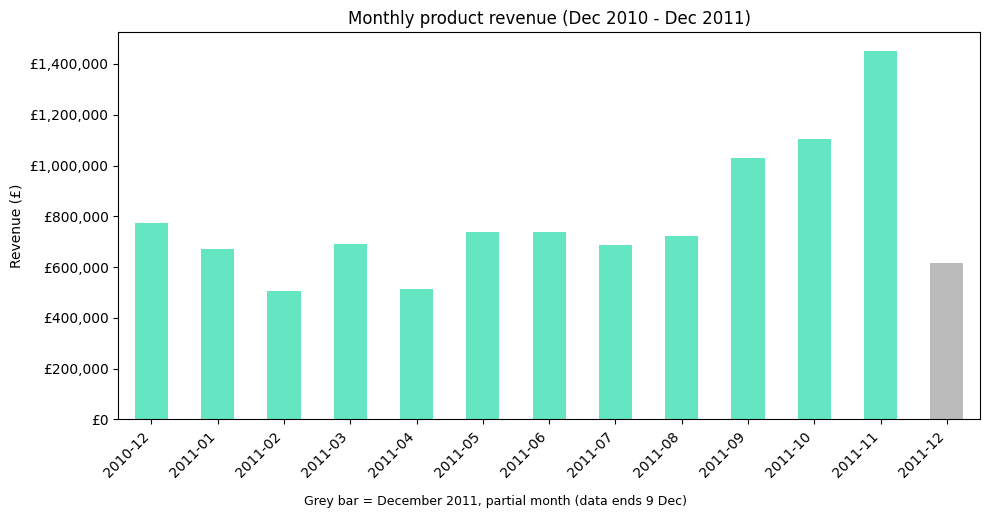

InvoiceMonth
2010-12     775641.0
2011-01     670380.0
2011-02     507800.0
2011-03     689834.0
2011-04     515378.0
2011-05     739953.0
2011-06     737559.0
2011-07     688219.0
2011-08     724216.0
2011-09    1028320.0
2011-10    1103314.0
2011-11    1452116.0
2011-12     614491.0
Name: Revenue, dtype: float64


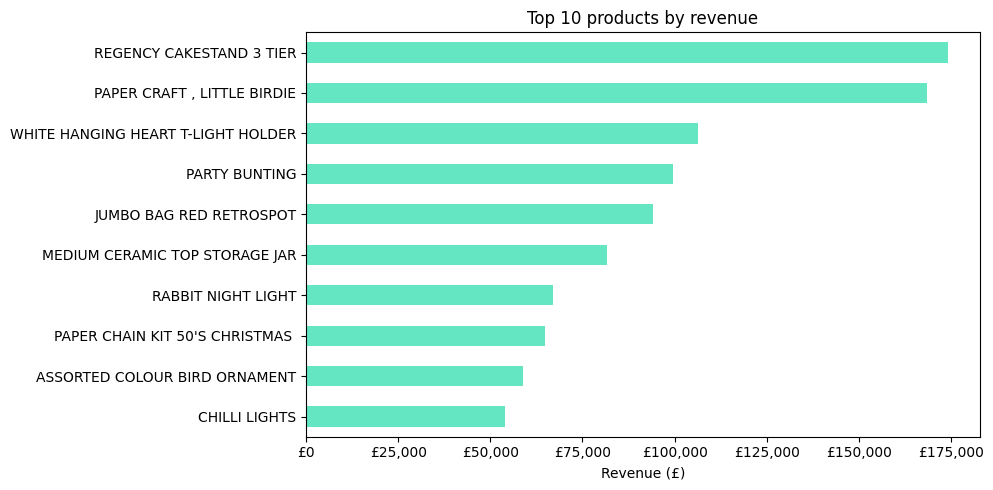


United Kingdom share of product revenue: 85.1%


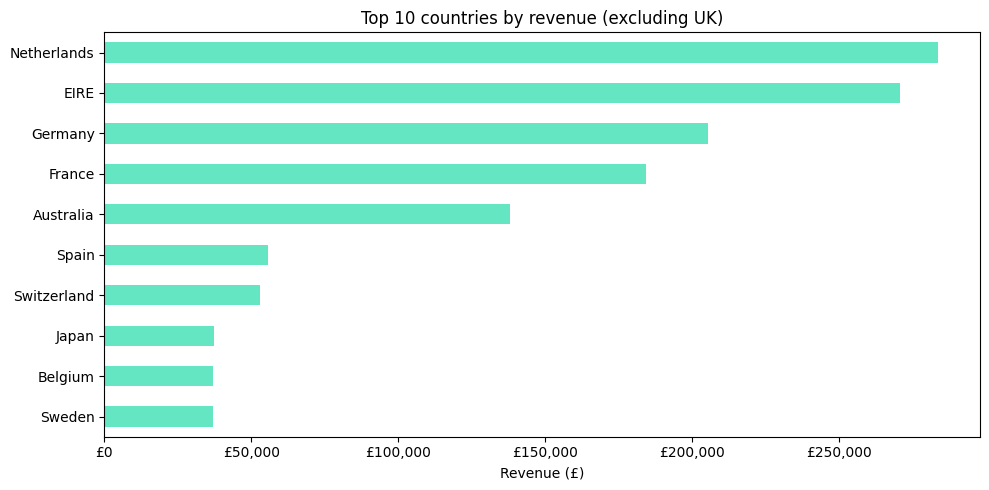

In [5]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

plt.rcParams["figure.figsize"] = (10, 5)

# ---------- 1. Monthly revenue ----------
monthly = products.groupby("InvoiceMonth")["Revenue"].sum()
monthly.index = monthly.index.astype(str)

colors = ["#64e6c2"] * len(monthly)
colors[-1] = "#bbbbbb"   # December 2011 is a partial month (data ends 9 Dec)

ax = monthly.plot(kind="bar", color=colors)
ax.set_title("Monthly product revenue (Dec 2010 - Dec 2011)")
ax.set_xlabel("")
ax.set_ylabel("Revenue (£)")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("£{x:,.0f}"))
plt.xticks(rotation=45, ha="right")
plt.figtext(0.5, -0.02, "Grey bar = December 2011, partial month (data ends 9 Dec)", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig("monthly_revenue.png", dpi=150, bbox_inches="tight")
plt.show()
print(monthly.round(0))

# ---------- 2. Top 10 products by revenue ----------
top_products = (products.groupby("Description")["Revenue"].sum()
                .sort_values(ascending=False).head(10))
ax = top_products.sort_values().plot(kind="barh", color="#64e6c2")
ax.set_title("Top 10 products by revenue")
ax.set_xlabel("Revenue (£)")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("£{x:,.0f}"))
plt.tight_layout()
plt.savefig("top_products.png", dpi=150, bbox_inches="tight")
plt.show()

# ---------- 3. Revenue by country ----------
by_country = products.groupby("Country")["Revenue"].sum().sort_values(ascending=False)
uk_share = by_country["United Kingdom"] / by_country.sum() * 100
print(f"\nUnited Kingdom share of product revenue: {uk_share:.1f}%")

top_non_uk = by_country.drop("United Kingdom").head(10)
ax = top_non_uk.sort_values().plot(kind="barh", color="#64e6c2")
ax.set_title("Top 10 countries by revenue (excluding UK)")
ax.set_xlabel("Revenue (£)")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("£{x:,.0f}"))
plt.tight_layout()
plt.savefig("top_countries.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
# The 10 largest product order lines
biggest = products.sort_values("Revenue", ascending=False).head(10)
print(biggest[["InvoiceNo", "InvoiceDate", "Description", "Quantity", "UnitPrice", "Revenue", "CustomerID"]])

# Is there a cancellation with the same customer, product and quantity?
canc = cancellations.assign(Quantity=cancellations["Quantity"].abs())
check = biggest.merge(canc, on=["CustomerID", "StockCode", "Quantity"],
                      how="left", suffixes=("", "_cancel"))
print("\nMatching cancellations:")
print(check[["Description", "Quantity", "InvoiceNo", "InvoiceDate", "InvoiceNo_cancel", "InvoiceDate_cancel"]])

       InvoiceNo         InvoiceDate                          Description  \
540421    581483 2011-12-09 09:15:00          PAPER CRAFT , LITTLE BIRDIE   
61619     541431 2011-01-18 10:01:00       MEDIUM CERAMIC TOP STORAGE JAR   
222680    556444 2011-06-10 15:28:00       PICNIC BASKET WICKER 60 PIECES   
348325    567423 2011-09-20 11:05:00  SET OF TEA COFFEE SUGAR TINS PANTRY   
160546    550461 2011-04-18 13:20:00   FAIRY CAKE FLANNEL ASSORTED COLOUR   
52711     540815 2011-01-11 12:55:00   FAIRY CAKE FLANNEL ASSORTED COLOUR   
421601    573003 2011-10-27 12:11:00                   RABBIT NIGHT LIGHT   
52709     540815 2011-01-11 12:55:00   WHITE HANGING HEART T-LIGHT HOLDER   
467804    576365 2011-11-14 17:55:00      PAPER CHAIN KIT 50'S CHRISTMAS    
160542    550461 2011-04-18 13:20:00   WHITE HANGING HEART T-LIGHT HOLDER   

        Quantity  UnitPrice    Revenue  CustomerID  
540421     80995       2.08  168469.60     16446.0  
61619      74215       1.04   77183.60     123

Cancelled product value (£): -475901.16
Gross product revenue (£):   10247221.87
Net product revenue (£):     9771320.71


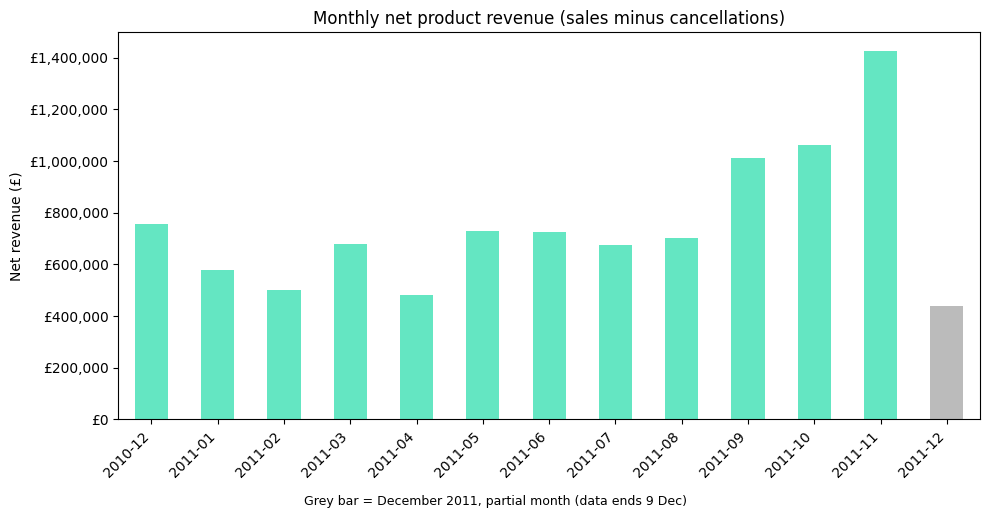

InvoiceMonth
2010-12     758093.0
2011-01     578855.0
2011-02     499464.0
2011-03     679329.0
2011-04     482062.0
2011-05     731005.0
2011-06     723845.0
2011-07     676812.0
2011-08     701290.0
2011-09    1011340.0
2011-10    1061701.0
2011-11    1427125.0
2011-12     440400.0
Name: Revenue, dtype: float64


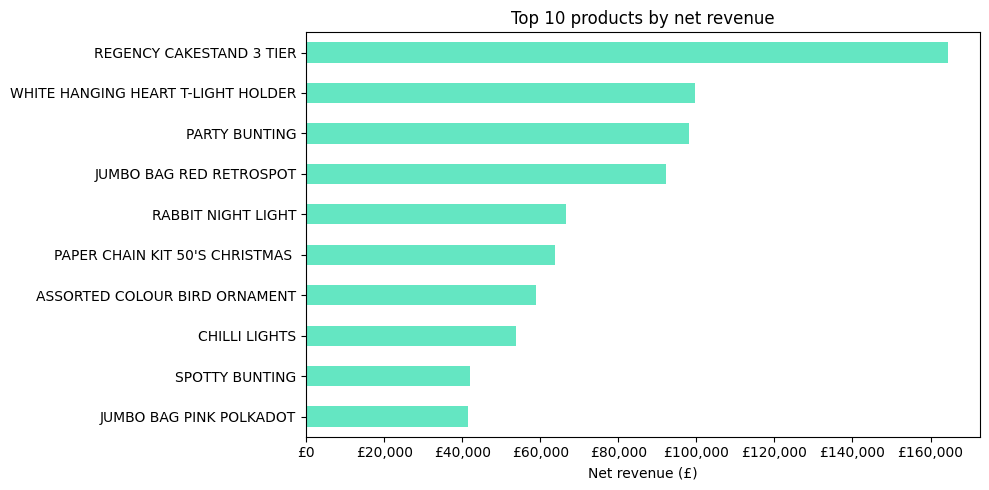

In [8]:
# Cancellations for real products only (same exclusions as before)
canc_codes = cancellations["StockCode"].astype(str)
canc_mask = canc_codes.isin(non_product_codes) | canc_codes.str.startswith("gift_")
canc_products = cancellations[~canc_mask & (cancellations["UnitPrice"] > 0)].copy()

# Cancellation Quantity is already negative, so Revenue comes out negative
canc_products["Revenue"] = canc_products["Quantity"] * canc_products["UnitPrice"]
canc_products["InvoiceMonth"] = canc_products["InvoiceDate"].dt.to_period("M")

print("Cancelled product value (£):", round(canc_products["Revenue"].sum(), 2))
print("Gross product revenue (£):  ", round(products["Revenue"].sum(), 2))

# Net = sales + (negative) cancellations
net = pd.concat([products, canc_products], ignore_index=True)
print("Net product revenue (£):    ", round(net["Revenue"].sum(), 2))

# ---------- Monthly net revenue ----------
monthly_net = net.groupby("InvoiceMonth")["Revenue"].sum()
monthly_net.index = monthly_net.index.astype(str)

colors = ["#64e6c2"] * len(monthly_net)
colors[-1] = "#bbbbbb"
ax = monthly_net.plot(kind="bar", color=colors)
ax.set_title("Monthly net product revenue (sales minus cancellations)")
ax.set_xlabel("")
ax.set_ylabel("Net revenue (£)")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("£{x:,.0f}"))
plt.xticks(rotation=45, ha="right")
plt.figtext(0.5, -0.02, "Grey bar = December 2011, partial month (data ends 9 Dec)", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig("monthly_net_revenue.png", dpi=150, bbox_inches="tight")
plt.show()
print(monthly_net.round(0))

# ---------- Top 10 products by net revenue ----------
top_net = net.groupby("Description")["Revenue"].sum().sort_values(ascending=False).head(10)
ax = top_net.sort_values().plot(kind="barh", color="#64e6c2")
ax.set_title("Top 10 products by net revenue")
ax.set_xlabel("Net revenue (£)")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("£{x:,.0f}"))
plt.tight_layout()
plt.savefig("top_products_net.png", dpi=150, bbox_inches="tight")
plt.show()


Customers analysed: 4333
type
Repeat      2828
One-time    1505
Name: count, dtype: int64

Repeat customers: 65.3%

Share of customer revenue (%):
type
One-time     6.5
Repeat      93.5
Name: revenue, dtype: float64

Median orders per customer: 2.0
Top 10% of customers = 60.3% of revenue

Average order value: £461.50 | Median: £301.63


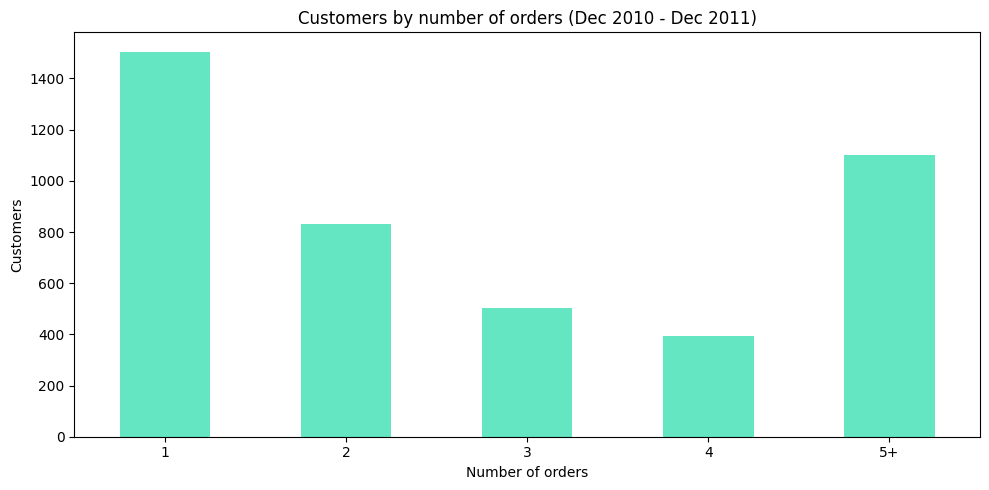

In [9]:
import numpy as np

# Remove the two orders we showed were entry errors (cancelled within minutes)
bad_invoices = ["581483", "541431"]
cust = customers_data[~customers_data["InvoiceNo"].isin(bad_invoices)].copy()

# One row per customer
summary = pd.DataFrame({
    "orders": cust.groupby("CustomerID")["InvoiceNo"].nunique(),
    "revenue": cust.groupby("CustomerID")["Revenue"].sum()
})
summary["type"] = np.where(summary["orders"] >= 2, "Repeat", "One-time")

n = len(summary)
print("Customers analysed:", n)
print(summary["type"].value_counts())
print(f"\nRepeat customers: {(summary['type']=='Repeat').mean()*100:.1f}%")

share = summary.groupby("type")["revenue"].sum() / summary["revenue"].sum() * 100
print("\nShare of customer revenue (%):")
print(share.round(1))

print("\nMedian orders per customer:", summary["orders"].median())

# Revenue concentration: top 10% of customers
top10 = summary["revenue"].sort_values(ascending=False).head(int(n * 0.1)).sum()
print(f"Top 10% of customers = {top10 / summary['revenue'].sum() * 100:.1f}% of revenue")

# Order value (one invoice = one order)
inv = cust.groupby("InvoiceNo")["Revenue"].sum()
print(f"\nAverage order value: £{inv.mean():.2f} | Median: £{inv.median():.2f}")

# Chart: customers by number of orders (5+ grouped)
bucket = summary["orders"].clip(upper=5).value_counts().sort_index()
bucket.index = ["1", "2", "3", "4", "5+"]
ax = bucket.plot(kind="bar", color="#64e6c2", rot=0)
ax.set_title("Customers by number of orders (Dec 2010 - Dec 2011)")
ax.set_xlabel("Number of orders")
ax.set_ylabel("Customers")
plt.tight_layout()
plt.savefig("orders_per_customer.png", dpi=150, bbox_inches="tight")
plt.show()